# 01 — EDA, annotation checks and CV split
Sections 0–5 are shared by both teammates; sections 6–7 prepare data for the torchvision models (Faster R-CNN, RetinaNet). Runs on CPU.

## 0. Setup
Imports and output folders for results and report plots.

In [1]:
import os, sys, json, math, time, shutil, subprocess, importlib, urllib.request
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import cv2
import torch
try:
    import pycocotools
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pycocotools"], check=True)

ON_KAGGLE = Path("/kaggle/working").exists()
WORK = Path("/kaggle/working") if ON_KAGGLE else Path.cwd()
IMG_OUT = WORK / "images" if ON_KAGGLE else Path.cwd().parent / "images"
IMG_OUT.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 100, "savefig.bbox": "tight", "savefig.dpi": 130})
print("Kaggle:", ON_KAGGLE, "| work dir:", WORK, "| plots:", IMG_OUT)

Kaggle: True | work dir: /kaggle/working | plots: /kaggle/working/images


Load the shared modules `common.py` and `tv_dataset.py` (working dir → attached Kaggle Dataset → GitHub) and fix the seed (42).

In [2]:
REPO_RAW = "https://raw.githubusercontent.com/KaplyshOlha/hw-2/main/notebooks"
for name in ["common.py", "tv_dataset.py"]:
    if (WORK / name).exists():
        continue
    found = [p for pat in ["*", "*/*", "*/*/*"] for p in sorted(Path("/kaggle/input").glob(f"{pat}/{name}"))]
    if found:
        shutil.copy(found[0], WORK / name)
    else:
        urllib.request.urlretrieve(f"{REPO_RAW}/{name}", WORK / name)
sys.path.insert(0, str(WORK))
import common, tv_dataset
importlib.reload(common); importlib.reload(tv_dataset)
common.seed_everything(common.SEED)
rng = np.random.default_rng(common.SEED)
print(common.__file__)

/kaggle/working/common.py


## 1. Dataset structure
Find the data root and list its top level.

In [3]:
EXPECTED = Path(f"/kaggle/input/{common.SLUG}")
ROOT = common.find_data_root()
print("expected path exists:", EXPECTED.exists(), "| using:", ROOT)
for p in sorted(ROOT.iterdir()):
    print(f"  {p.name:<24}", "dir" if p.is_dir() else f"{p.stat().st_size / 1e6:.1f} MB")

expected path exists: False | using: /kaggle/input/competitions/multiple-object-video-detection-hw-2-ucu-ai-2026
  test                     dir
  test_images.csv          0.3 MB
  train                    dir
  val                      dir


Count clips, frames, label files and ignore files per split and compare them with the competition description.

In [4]:
expected = {"train": (56, 24201), "val": (7, 2846), "test": (48, 3811)}
rows = []
for split, (exp_clips, exp_frames) in expected.items():
    d = ROOT / split
    clips = sorted(c.name for c in (d / "images").iterdir() if c.is_dir())
    count = lambda sub: sum(len(os.listdir(d / sub / c)) for c in clips if (d / sub / c).exists())
    rows.append(dict(split=split, clips=len(clips), exp_clips=exp_clips, frames=count("images"),
                     exp_frames=exp_frames, label_files=count("labels"), ignore_files=count("ignore")))
pd.DataFrame(rows).set_index("split")

,clips,exp_clips,frames,exp_frames,label_files,ignore_files
split,,,,,,
train,56,56,24201,24201,24201,18090
val,7,7,2846,2846,2846,1434
test,48,48,3811,3811,0,0


**Observations.** Counts match the description exactly (56 / 7 / 48 clips, 24,201 / 2,846 / 3,811 frames). Every labelled frame has a label file; ignore files exist only for frames with ignored regions.

Check `data.yaml`, COCO categories and `test_images.csv`. The data has no `sample_submission.csv`, so the reference submission is built from `test_images.csv`.

In [5]:
print((ROOT / "train" / "data.yaml").read_text())
with open(ROOT / "val" / "annotations_coco.json") as f:
    print("COCO categories:", [(c["id"], c["name"]) for c in json.load(f)["categories"]])
test_index = common.load_test_index(ROOT)
SAMPLE_SUB = next(iter(sorted(ROOT.glob("*sample*submission*.csv")) + sorted(ROOT.glob("*/*sample*submission*.csv"))), None)
print("sample submission:", SAMPLE_SUB)
sample_sub = pd.read_csv(SAMPLE_SUB) if SAMPLE_SUB else test_index[["image_id"]].assign(PredictionString="")
print("test rows:", len(test_index), "| sample rows:", len(sample_sub),
      "| same ids:", test_index.image_id.tolist() == sample_sub.image_id.tolist())
display(test_index.head(3)); display(sample_sub.head(3))

path: .
train: images
val: images
nc: 8
names: ["person", "bicycle", "car", "van", "truck", "tricycle", "bus", "motor"]

COCO categories: [(1, 'person'), (2, 'bicycle'), (3, 'car'), (4, 'van'), (5, 'truck'), (6, 'tricycle'), (7, 'bus'), (8, 'motor')]
sample submission: None
test rows: 3811 | sample rows: 3811 | same ids: True


,image_id,file_name,clip,frame,width,height,path
0,clip_001_0000001,test/images/clip_001/0000001.jpg,clip_001,1,1920,1080,/kaggle/input/competitions/multiple-object-vid...
1,clip_001_0000002,test/images/clip_001/0000002.jpg,clip_001,2,1920,1080,/kaggle/input/competitions/multiple-object-vid...
2,clip_001_0000003,test/images/clip_001/0000003.jpg,clip_001,3,1920,1080,/kaggle/input/competitions/multiple-object-vid...


,image_id,PredictionString
0,clip_001_0000001,
1,clip_001_0000002,
2,clip_001_0000003,


**Observations.** Class ids are consistent: YOLO 0–7, COCO 1–8. The reference submission matches `test_images.csv` one to one.

## 2. Loading and verifying annotations
Merge train and val COCO annotations into one frame table (`images`) and one box table (`anns`) with a global `img_id`. The COCO file stores every ignored region 8 times (once per class), so `load_gt` keeps one copy.

In [6]:
t0 = time.time()
images, anns = common.load_gt(ROOT, cache=WORK / "gt_cache.pkl")
obj = (anns[anns.iscrowd == 0]
       .merge(images[["img_id", "split", "clip", "width", "height"]], on="img_id")
       .sort_values("img_id", kind="stable").reset_index(drop=True))
ign = anns[anns.iscrowd == 1].reset_index(drop=True)
obj["cname"] = obj.cls.map(dict(enumerate(common.CLASSES)))
print(f"{time.time() - t0:.0f}s | frames {len(images)} | clips {images['clip'].nunique()} | "
      f"boxes {len(obj)} | ignored regions {len(ign)}")
images.head(3)

16s | frames 27047 | clips 63 | boxes 1219648 | ignored regions 67838


,img_id,split,orig_id,clip,frame_id,width,height,path
0,0,train,1,uav0000013_00000_v,1,1344,756,/kaggle/input/competitions/multiple-object-vid...
1,1,train,2,uav0000013_00000_v,2,1344,756,/kaggle/input/competitions/multiple-object-vid...
2,2,train,3,uav0000013_00000_v,3,1344,756,/kaggle/input/competitions/multiple-object-vid...


**Observations.** 27,047 frames, 63 clips, 1.22 M boxes and 67.8 k ignored regions (542.7 k before removing the 8 copies).

How the original VisDrone categories (`orig_category_id`) map to our 8 classes.

In [7]:
pd.crosstab(anns.orig_cat, anns.cls.map(dict(enumerate(common.CLASSES))).fillna("ignored (iscrowd=1)"))

cls,bicycle,bus,car,ignored (iscrowd=1),motor,person,tricycle,truck,van
orig_cat,,,,,,,,,
0,0,0,0,66363,0,0,0,0,0
1,0,0,0,0,0,266709,0,0,0
2,0,0,0,0,0,112304,0,0,0
3,46277,0,0,0,0,0,0,0,0
4,0,0,537122,0,0,0,0,0,0
5,0,0,0,0,0,0,0,0,53782
6,0,0,0,0,0,0,0,31857,0
7,0,0,0,0,0,0,32107,0,0
8,0,0,0,0,0,0,14729,0,0


**Observations.**
- `person` = pedestrian (1) + people (2); `tricycle` = tricycle (7) + awning-tricycle (8).
- Non-target classes — ignored regions (0) and *others* (11) — are both stored as `iscrowd=1`. We treat them as "don't care": gray fill in training, ignored in evaluation.

Compare YOLO labels (`labels/`, `ignore/`) with COCO on 30 random frames and look for zero-size or duplicate GT boxes.

In [8]:
def yolo_to_xywh(path, w, h, has_cls):
    if not path.exists() or path.stat().st_size == 0:
        return np.zeros((0, 5 if has_cls else 4))
    a = np.loadtxt(path, ndmin=2)
    b = a[:, 1:] if has_cls else a
    xywh = np.column_stack([(b[:, 0] - b[:, 2] / 2) * w, (b[:, 1] - b[:, 3] / 2) * h, b[:, 2] * w, b[:, 3] * h])
    return np.column_stack([a[:, 0], xywh]) if has_cls else xywh

def max_diff(a, b):
    if len(a) != len(b):
        return np.inf
    if len(a) == 0:
        return 0.0
    sort = lambda m: m[np.lexsort(np.round(m).T[::-1])]
    return float(np.abs(sort(a) - sort(b)).max())

checks = []
for iid in rng.choice(images.img_id.to_numpy(), 30, replace=False):
    r = images.loc[iid]
    d, stem = ROOT / r.split, Path(r.path).stem
    lab = yolo_to_xywh(d / "labels" / r["clip"] / f"{stem}.txt", r.width, r.height, True)
    ig = yolo_to_xywh(d / "ignore" / r["clip"] / f"{stem}.txt", r.width, r.height, False)
    o, g = obj[obj.img_id == iid], ign[ign.img_id == iid]
    checks.append(dict(n_yolo=len(lab), n_coco=len(o), n_ign_txt=len(ig), n_ign_coco=len(g),
                       diff_boxes=max_diff(lab, o[["cls", "x", "y", "w", "h"]].to_numpy(float)),
                       diff_ign=max_diff(ig, g[["x", "y", "w", "h"]].to_numpy(float))))
checks = pd.DataFrame(checks)
print("max coordinate diff (px):", checks[["diff_boxes", "diff_ign"]].max().round(3).to_dict(),
      "| frames with count mismatch:",
      int(((checks.n_yolo != checks.n_coco) | (checks.n_ign_txt != checks.n_ign_coco)).sum()), "/ 30")
print("zero-size GT boxes:", int(((obj.w <= 0) | (obj.h <= 0)).sum()),
      "| duplicate GT boxes:", int(obj.duplicated(["img_id", "cls", "x", "y", "w", "h"]).sum()))

max coordinate diff (px): {'diff_boxes': 0.003, 'diff_ign': 0.002} | frames with count mismatch: 0 / 30
zero-size GT boxes: 0 | duplicate GT boxes: 0


**Observations.** YOLO and COCO agree (max difference 0.003 px, no count mismatches); there are no zero-size or duplicate boxes. The first run showed count mismatches for ignored regions, which is how we found the 8× duplication.

## 3. EDA
### 3.1 Class distribution
Box counts per class (train + val), log scale.

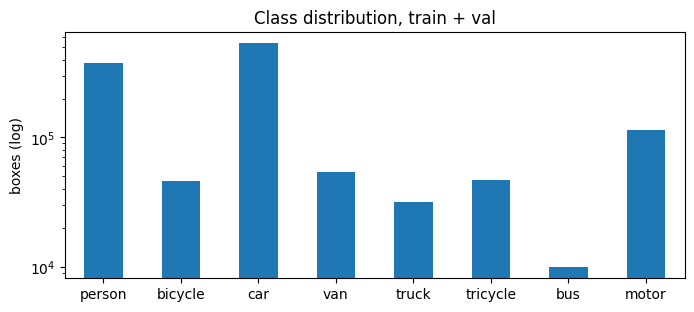

split,train,val,total,share_%
cname,,,,
person,328701,50312,379013,31.08
bicycle,40255,6022,46277,3.79
car,505301,31821,537122,44.04
van,46940,6842,53782,4.41
truck,30498,1359,31857,2.61
tricycle,41349,5487,46836,3.84
bus,9653,264,9917,0.81
motor,102819,12025,114844,9.42


In [9]:
cls_counts = pd.crosstab(obj.cname, obj.split).reindex(common.CLASSES).fillna(0).astype(int)
cls_counts["total"] = cls_counts.sum(axis=1)
cls_counts["share_%"] = (100 * cls_counts.total / cls_counts.total.sum()).round(2)
fig, ax = plt.subplots(figsize=(8, 3.2))
cls_counts.total.plot.bar(ax=ax, logy=True, color="tab:blue", rot=0)
ax.set_ylabel("boxes (log)"); ax.set_xlabel(""); ax.set_title("Class distribution, train + val")
fig.savefig(IMG_OUT / "class_distribution.png"); plt.show()
cls_counts

**Observations.** Strong class imbalance: car 44 % and person 31 % of all boxes; bus 0.8 %, truck 2.6 %, bicycle / tricycle / van about 4 % each. We report per-class AP, not only mAP; rare classes are candidates for oversampling or copy-paste in the final pipeline.

Class presence and class shares per clip (clips sorted by car share).

clips containing class: {'person': 62, 'bicycle': 46, 'car': 55, 'van': 52, 'truck': 44, 'tricycle': 44, 'bus': 25, 'motor': 56}


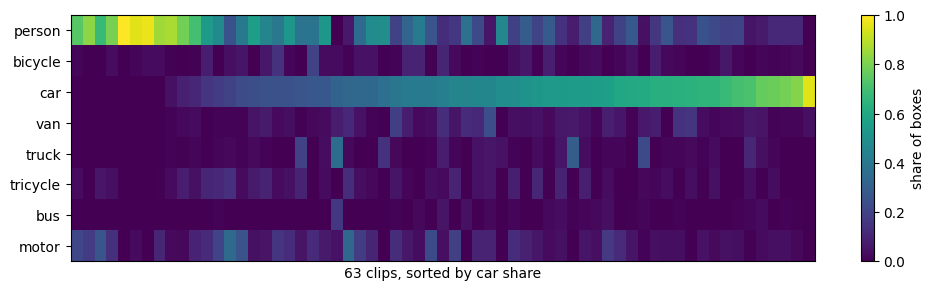

In [10]:
cnt = pd.crosstab(obj["clip"], obj.cname).reindex(columns=common.CLASSES, fill_value=0)
share = cnt.div(cnt.sum(axis=1), axis=0)
print("clips containing class:", (cnt > 0).sum().to_dict())
fig, ax = plt.subplots(figsize=(12, 3.2))
im = ax.imshow(share.sort_values("car").T.values, aspect="auto", cmap="viridis")
ax.set_yticks(range(len(common.CLASSES)), common.CLASSES); ax.set_xticks([])
ax.set_xlabel(f"{len(share)} clips, sorted by car share"); fig.colorbar(im, ax=ax, label="share of boxes")
fig.savefig(IMG_OUT / "class_share_per_clip.png"); plt.show()

**Observations.** The class mix differs a lot between clips: bus appears in only 25 of 63 clips, truck and tricycle in 44. With 21 validation clips per fold, AP for rare classes will vary between folds.

### 3.2 Object sizes
Box size as √area in original pixels; shares of COCO small (< 32²), medium and large boxes per class.

In [11]:
obj["area"] = obj.w * obj.h
obj["sqrt_area"] = np.sqrt(obj.area.astype(np.float64))
obj["size_cat"] = pd.cut(obj.area, [0, 32 ** 2, 96 ** 2, np.inf], right=False,
                         labels=["small", "medium", "large"]).astype(str)
size_tab = (pd.crosstab(obj.cname, obj.size_cat, normalize="index").mul(100)
            .reindex(index=common.CLASSES, columns=["small", "medium", "large"]).fillna(0))
size_tab.loc["ALL"] = obj.size_cat.value_counts(normalize=True).reindex(["small", "medium", "large"]).fillna(0).values * 100
size_tab["median_sqrt_area_px"] = obj.groupby("cname").sqrt_area.median().reindex(size_tab.index)
size_tab.loc["ALL", "median_sqrt_area_px"] = obj.sqrt_area.median()
size_tab.round(1)

size_cat,small,medium,large,median_sqrt_area_px
cname,,,,
person,37.5,61.7,0.7,36.7
bicycle,21.6,75.6,2.8,43.9
car,15.9,64.9,19.2,57.5
van,19.4,63.8,16.7,51.3
truck,9.1,57.5,33.4,73.9
tricycle,20.7,65.3,14.0,54.5
bus,4.0,39.3,56.7,111.7
motor,31.4,66.8,1.7,39.8
ALL,24.4,64.1,11.6,46.4


**Observations.** In original resolution only 24 % of boxes are COCO-small (person 38 %, motor 31 %); most buses are large. The median size is 46 px.

Size distribution per class, and sizes after resizing the longest side to 1280 / 640 px (what the model actually sees).

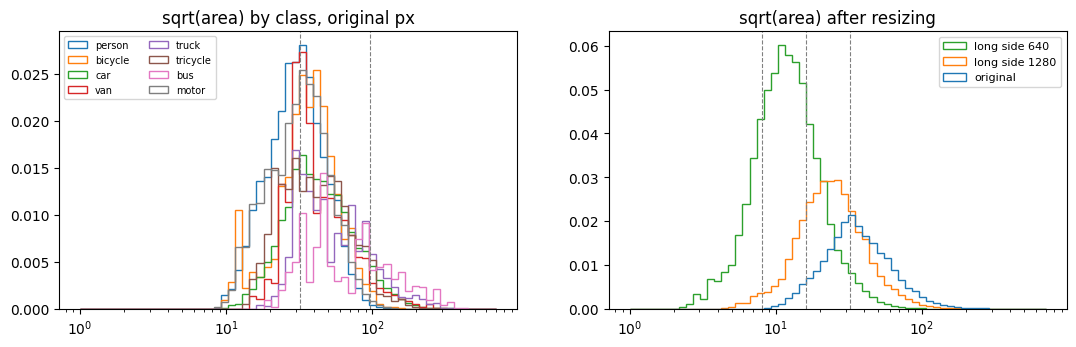

,0.05,0.25,0.5,0.75,0.95,<8px %
original,19.9,32.3,46.4,68.8,130.3,0.0
long side 1280,13.5,21.8,30.6,44.0,82.7,0.6
long side 640,6.8,10.9,15.3,22.0,41.3,9.7


In [12]:
long_side = np.maximum(obj.width, obj.height)
obj["sqrt_area_640"] = obj.sqrt_area * 640 / long_side
bins = np.logspace(0, np.log10(obj.sqrt_area.max() + 1), 60)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
for c in common.CLASSES:
    axes[0].hist(obj.sqrt_area[obj.cname == c], bins=bins, histtype="step", density=True, label=c)
axes[0].set_title("sqrt(area) by class, original px"); axes[0].legend(fontsize=7, ncol=2)
axes[1].hist([obj.sqrt_area, obj.sqrt_area * 1280 / long_side, obj.sqrt_area_640], bins=bins,
             histtype="step", density=True, label=["original", "long side 1280", "long side 640"])
axes[1].set_title("sqrt(area) after resizing")
for ax, lines in [(axes[0], [32, 96]), (axes[1], [8, 16, 32])]:
    ax.set_xscale("log")
    for v in lines:
        ax.axvline(v, ls="--", c="gray", lw=0.8)
axes[1].legend(fontsize=8)
fig.savefig(IMG_OUT / "object_sizes.png"); plt.show()
q = [0.05, 0.25, 0.5, 0.75, 0.95]
size_q = pd.DataFrame({"original": obj.sqrt_area.quantile(q), "long side 1280": (obj.sqrt_area * 1280 / long_side).quantile(q),
                       "long side 640": obj.sqrt_area_640.quantile(q)}).T
size_q["<8px %"] = [100 * (s < 8).mean() for s in [obj.sqrt_area, obj.sqrt_area * 1280 / long_side, obj.sqrt_area_640]]
size_q.round(1)

**Observations.** What matters is the size after resizing. At 640 px the median object is 15 px and 9.7 % of objects are smaller than 8 px (the stride of the finest FPN level); at 1280 px only 0.6 % are. 640 px stays our fixed protocol for comparing models, but the final pipeline should use a higher input resolution or tiling (SAHI).

Frame resolutions in train / val / test and per-clip statistics.

split,test,train,val,All
resolution,,,,
1344x756,7,11,2,20
1360x764,18,0,0,18
1360x765,0,1,0,1
1904x1071,0,30,2,32
1904x1072,4,0,0,4
1920x1080,11,1,0,12
2688x1512,0,11,1,12
2720x1530,0,2,1,3
3840x2160,0,0,1,1


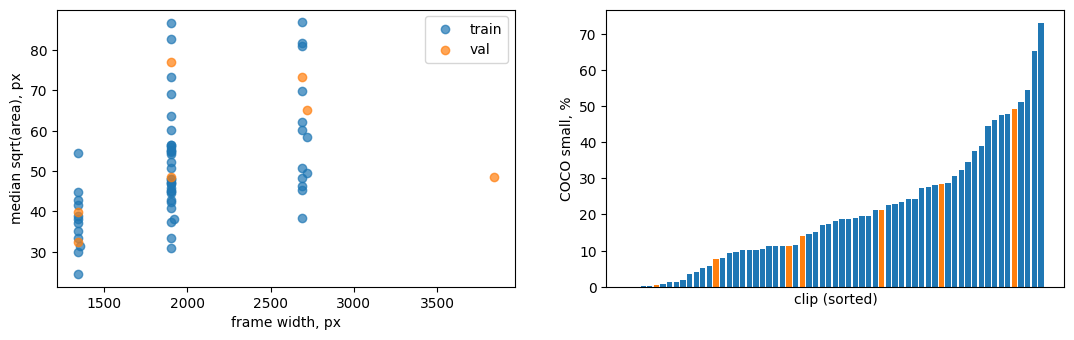

,frames,boxes,small_%,median_sqrt_area
count,63.0,63.0,63.0,63.0
mean,429.3,19359.5,20.7,51.2
std,272.4,15301.4,17.0,14.8
min,58.0,706.0,0.0,24.5
25%,227.5,8840.0,9.4,41.2
50%,363.0,16436.0,18.1,48.1
75%,547.5,24805.5,28.3,57.5
max,1424.0,64916.0,73.1,86.8


In [13]:
res = pd.concat([images.groupby("clip").first()[["split", "width", "height"]],
                 test_index.groupby("clip").first()[["width", "height"]].assign(split="test")])
res["resolution"] = res.width.astype(str) + "x" + res.height.astype(str)
display(pd.crosstab(res.resolution, res.split, margins=True))

g = obj.groupby("clip")
clip_stats = images.groupby("clip").agg(split=("split", "first"), frames=("img_id", "size"),
                                        width=("width", "first"), height=("height", "first"))
clip_stats["boxes"] = g.size().reindex(clip_stats.index, fill_value=0)
clip_stats["small_%"] = (obj.size_cat == "small").groupby(obj["clip"]).mean().mul(100)
clip_stats["median_sqrt_area"] = g.sqrt_area.median()
clip_stats["top_class"] = g.cname.agg(lambda s: s.value_counts().index[0])

fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
for sp, c in [("train", "tab:blue"), ("val", "tab:orange")]:
    cs = clip_stats[clip_stats.split == sp]
    axes[0].scatter(cs.width, cs.median_sqrt_area, c=c, label=sp, alpha=0.7)
axes[0].set_xlabel("frame width, px"); axes[0].set_ylabel("median sqrt(area), px"); axes[0].legend()
cs = clip_stats.sort_values("small_%")
axes[1].bar(range(len(cs)), cs["small_%"], color=np.where(cs.split == "val", "tab:orange", "tab:blue"))
axes[1].set_xlabel("clip (sorted)"); axes[1].set_ylabel("COCO small, %"); axes[1].set_xticks([])
fig.savefig(IMG_OUT / "sizes_per_clip.png"); plt.show()
clip_stats[["frames", "boxes", "small_%", "median_sqrt_area"]].describe().round(1)

**Observations.**
- Resolution ranges from 680×382 to 3840×2160. Test contains resolutions not seen in training (680×382 and 960×540, 8 clips) and many more 1920×1080 clips (11 vs 1). Multi-scale training augmentation should help.
- Lower-resolution clips have smaller objects in pixels; the share of small objects per clip ranges from 0 % to 73 %.

### 3.3 Scene density
Objects per frame, overall and per clip; dashed lines mark 100 / 300 / 500 detections.

{'count': 27047.0, 'mean': 45.1, 'std': 31.1, 'min': 0.0, '50%': 42.0, '90%': 90.0, '99%': 140.0, 'max': 180.0}
{'>100': 2034, '>300': 0, '>500': 0} frames with no objects: 3


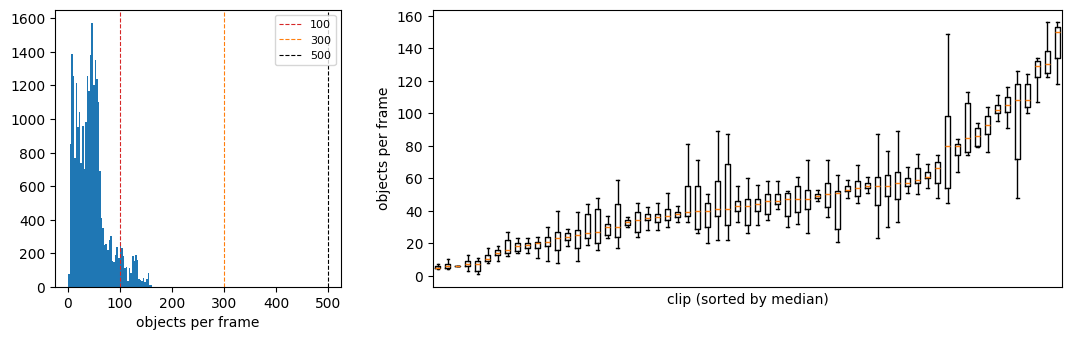

In [14]:
images["n_obj"] = obj.groupby("img_id").size().reindex(images.index, fill_value=0)
print(images.n_obj.describe(percentiles=[0.5, 0.9, 0.99]).round(1).to_dict())
print({f">{k}": int((images.n_obj > k).sum()) for k in [100, 300, 500]}, "frames with no objects:", int((images.n_obj == 0).sum()))
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6), gridspec_kw={"width_ratios": [1, 2.2]})
axes[0].hist(images.n_obj, bins=60, color="tab:blue")
for v, c in [(100, "tab:red"), (300, "tab:orange"), (500, "k")]:
    axes[0].axvline(v, ls="--", c=c, lw=0.8, label=f"{v}")
axes[0].set_xlabel("objects per frame"); axes[0].legend(fontsize=8)
order = images.groupby("clip").n_obj.median().sort_values().index
axes[1].boxplot([images.n_obj[images["clip"] == c] for c in order], showfliers=False)
axes[1].set_xticks([]); axes[1].set_xlabel("clip (sorted by median)"); axes[1].set_ylabel("objects per frame")
fig.savefig(IMG_OUT / "objects_per_frame.png"); plt.show()
clip_stats["obj_per_frame"] = images.groupby("clip").n_obj.mean()

**Observations.** Mean 45, median 42 and max 180 objects per frame; 2,034 frames (7.5 %) have more than 100. Torchvision's default `detections_per_img=100` would cut correct detections, so we use 300 (Kaggle scores up to 500). RT-DETR's default 300 queries are enough.

### 3.4 Ignored regions
Ignore mask per frame: the share of the frame it covers and, for every box, the share of the box inside it.

In [15]:
oid = obj.img_id.to_numpy()
oxywh = obj[["x", "y", "w", "h"]].to_numpy(np.float64)
cover = np.zeros(len(obj), np.float32)
frac = {}
t0 = time.time()
for iid, g in ign.groupby("img_id"):
    m = common.ignore_mask(images.at[iid, "height"], images.at[iid, "width"], g[["x", "y", "w", "h"]].to_numpy())
    frac[iid] = m.mean()
    a, b = np.searchsorted(oid, [iid, iid + 1])
    if b > a:
        cover[a:b] = common.box_coverage(oxywh[a:b], m)
obj["ign_cover"] = cover
images["ign_frac"] = pd.Series(frac, dtype=float).reindex(images.index, fill_value=0.0)
images["n_ign"] = ign.groupby("img_id").size().reindex(images.index, fill_value=0)
has = images.n_ign > 0
print(f"{time.time() - t0:.0f}s | frames with ignore: {100 * has.mean():.1f}% | "
      f"regions per such frame: {images.n_ign[has].mean():.1f} | covered area there: {100 * images.ign_frac[has].mean():.1f}% | "
      f"boxes >=50% inside ignore: {100 * (obj.ign_cover >= 0.5).mean():.2f}%")

70s | frames with ignore: 72.2% | regions per such frame: 3.5 | covered area there: 3.2% | boxes >=50% inside ignore: 1.09%


**Observations.** 72 % of frames have ignored regions (3.5 per frame), but they cover only 3.2 % of these frames. 1.1 % of boxes lie at least 50 % inside an ignored region; the dataset drops them because the object is painted over.

Distribution of the ignored area and its variation across clips; share of covered boxes per class.

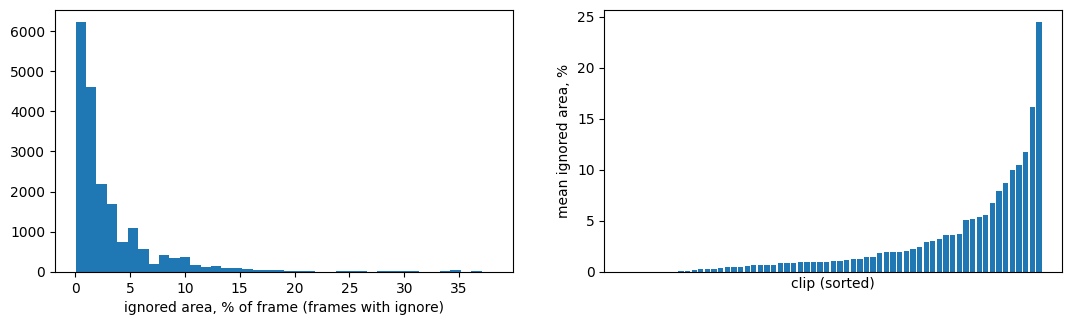

cname,person,bicycle,car,van,truck,tricycle,bus,motor
"boxes >=50% in ignore, %",1.4,1.7,0.94,1.12,0.56,1.46,0.37,0.56


In [16]:
clip_stats["ignore_frames_%"] = has.groupby(images["clip"]).mean().mul(100)
clip_stats["ignore_area_%"] = images.groupby("clip").ign_frac.mean().mul(100)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.4))
axes[0].hist(100 * images.ign_frac[has], bins=40); axes[0].set_xlabel("ignored area, % of frame (frames with ignore)")
cs = clip_stats.sort_values("ignore_area_%")
axes[1].bar(range(len(cs)), cs["ignore_area_%"]); axes[1].set_xticks([])
axes[1].set_xlabel("clip (sorted)"); axes[1].set_ylabel("mean ignored area, %")
fig.savefig(IMG_OUT / "ignore_regions.png"); plt.show()
(obj.ign_cover >= 0.5).groupby(obj.cname).mean().mul(100).reindex(common.CLASSES).round(2).rename("boxes >=50% in ignore, %").to_frame().T

**Observations.** The ignored area is concentrated in a few clips (dense parking lots, crowds). Covered boxes are spread evenly across classes (0.4–1.7 %), so dropping them does not bias any class.

### 3.5 Occlusion and truncation
Occlusion (0 none, 1 partial, 2 heavy) and truncation levels per class.

In [17]:
occ = pd.crosstab(obj.cname, obj.occlusion, normalize="index").mul(100).reindex(common.CLASSES)
trn = pd.crosstab(obj.cname, obj.truncation, normalize="index").mul(100).reindex(common.CLASSES)
pd.concat([occ, trn], axis=1, keys=["occlusion, %", "truncation, %"]).round(1)

occlusion, %             truncation, %      
                    0     1     2             0     1
cname                                                
person           53.0  40.9   6.1          97.8   2.2
bicycle          41.7  55.1   3.2          99.0   1.0
car              56.2  38.9   4.9          94.2   5.8
van              54.9  41.5   3.5          94.3   5.7
truck            34.6  49.8  15.6          88.7  11.3
tricycle         41.7  55.6   2.6          95.8   4.2
bus              56.6  41.3   2.0          86.3  13.7
motor            51.9  41.7   6.4          96.7   3.3

**Observations.** About half of all objects are partly occluded. Trucks have the most heavy occlusion (15.6 %); trucks and buses are the most often truncated (11–14 %), since large vehicles are often cut by the frame edge.

### 3.6 Temporal correlation
For different frame strides: frames and boxes left, share of unique tracks still seen, and pixel difference between frames t and t + stride.

track length, frames: {'count': 8100.0, 'mean': 151.0, 'std': 140.0, 'min': 1.0, '25%': 49.0, '50%': 105.0, '75%': 213.0, 'max': 1255.0}


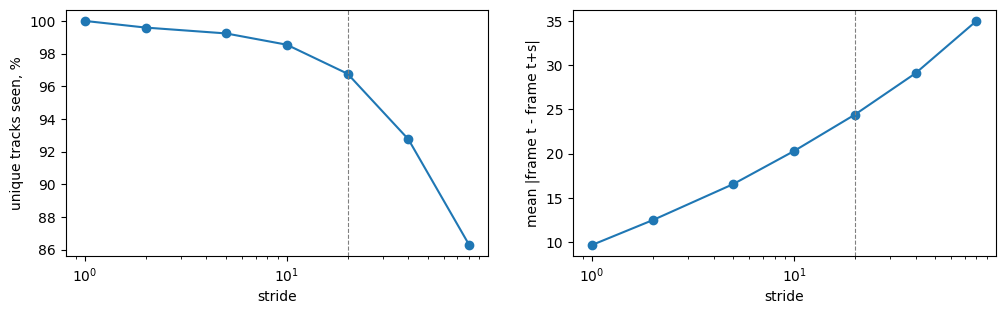

,frames,boxes,tracks_seen_pct,pixel_diff_t_vs_t_plus_stride
stride,,,,
1,27047,1219648,100.0,9.700000
2,13539,610569,99.6,12.500000
5,5439,245785,99.2,16.600000
10,2734,123834,98.5,20.299999
20,1384,62932,96.8,24.400000
40,705,32081,92.8,29.100000
80,370,17053,86.3,35.000000


In [18]:
track_key = obj["clip"].astype(str) + "_" + obj.track_id.astype(str)
n_tracks = track_key.nunique()
sample_clips = rng.choice(images["clip"].unique(), min(8, images["clip"].nunique()), replace=False)
small = lambda p: cv2.resize(cv2.imread(p, cv2.IMREAD_GRAYSCALE), (160, 90)).astype(np.float32)
rows = []
for s in [1, 2, 5, 10, 20, 40, 80]:
    keep = common.subsample(images, s).index
    sel = obj.img_id.isin(keep)
    diffs = []
    for c in sample_clips:
        fr = images[images["clip"] == c].sort_values("frame_id")
        if len(fr) > s:
            diffs.append(np.abs(small(fr.path.iloc[0]) - small(fr.path.iloc[s])).mean())
    rows.append(dict(stride=s, frames=len(keep), boxes=int(sel.sum()),
                     tracks_seen_pct=100 * track_key[sel].nunique() / n_tracks,
                     pixel_diff_t_vs_t_plus_stride=np.mean(diffs) if diffs else np.nan))
stride_tab = pd.DataFrame(rows).set_index("stride")
track_len = track_key.value_counts()
print("track length, frames:", track_len.describe(percentiles=[0.25, 0.5, 0.75]).round(0).to_dict())
fig, axes = plt.subplots(1, 2, figsize=(12, 3.2))
stride_tab.tracks_seen_pct.plot(ax=axes[0], marker="o", logx=True); axes[0].set_ylabel("unique tracks seen, %")
stride_tab.pixel_diff_t_vs_t_plus_stride.plot(ax=axes[1], marker="o", logx=True); axes[1].set_ylabel("mean |frame t - frame t+s|")
for ax in axes:
    ax.axvline(common.TRAIN_STRIDE, ls="--", c="gray", lw=0.8)
fig.savefig(IMG_OUT / "stride_analysis.png"); plt.show()
stride_tab.round(1)

**Observations.** Neighbouring frames are almost identical (median track length 105 frames). Stride 20 keeps 5 % of frames but 96.8 % of unique objects, so we use it for all comparison runs; the final model can use a smaller stride.

## 4. Visual check of annotations
GT boxes (colour = class) and ignored regions (hatched) on the densest frame, the frame with the smallest objects, the frame with the largest ignored area and three random frames.

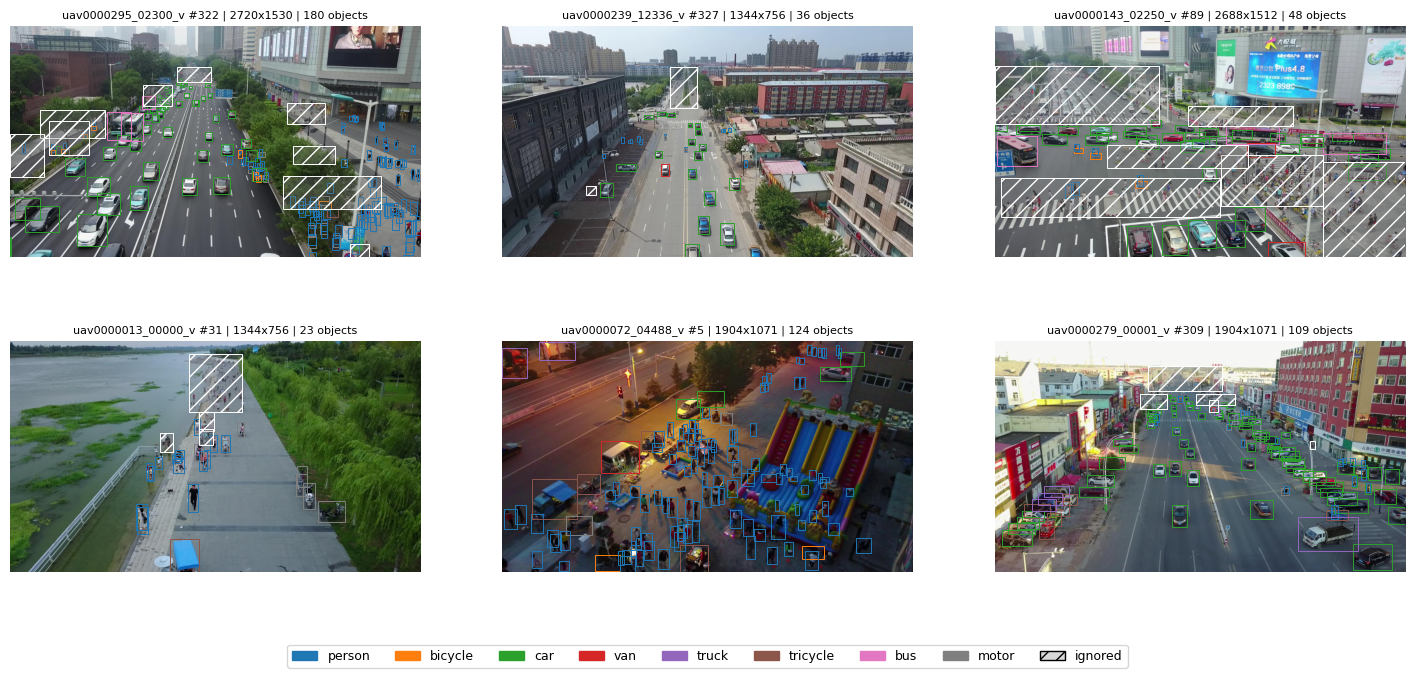

In [19]:
COLORS = plt.cm.tab10(np.arange(len(common.CLASSES)))
ocls = obj.cls.to_numpy()

def draw_frame(ax, iid, fill=False):
    r = images.loc[iid]
    img = cv2.cvtColor(cv2.imread(r.path), cv2.COLOR_BGR2RGB)
    g = ign.loc[ign.img_id == iid, ["x", "y", "w", "h"]].to_numpy()
    if fill and len(g):
        img = common.fill_ignore(img, common.ignore_mask(*img.shape[:2], g))
    ax.imshow(img)
    a, b = np.searchsorted(oid, [iid, iid + 1])
    for (x, y, w, h), c in zip(oxywh[a:b], ocls[a:b]):
        ax.add_patch(mpatches.Rectangle((x, y), w, h, fill=False, ec=COLORS[c], lw=0.7))
    for x, y, w, h in g:
        ax.add_patch(mpatches.Rectangle((x, y), w, h, fill=not fill, fc=(0.5, 0.5, 0.5, 0.3), ec="white", hatch="//", lw=0.7))
    ax.set_title(f"{r['clip']} #{r.frame_id} | {r.width}x{r.height} | {b - a} objects", fontsize=8)
    ax.axis("off")

med = obj.groupby("img_id").sqrt_area.median()
med = med[images.n_obj.reindex(med.index) >= 20]
pick = [images.n_obj.idxmax(), med.idxmin() if len(med) else images.index[0], images.ign_frac.idxmax()]
other = images[~images["clip"].isin(images.loc[pick, "clip"])]
pick += other.groupby("clip").sample(1, random_state=common.SEED).sample(3, random_state=common.SEED).index.tolist()
legend = [mpatches.Patch(color=COLORS[i], label=c) for i, c in enumerate(common.CLASSES)]
legend.append(mpatches.Patch(fc=(0.5, 0.5, 0.5, 0.3), ec="k", hatch="//", label="ignored"))
fig, axes = plt.subplots(2, 3, figsize=(18, 7.5))
for ax, iid in zip(axes.ravel(), pick):
    draw_frame(ax, iid)
fig.legend(handles=legend, loc="lower center", ncol=9, fontsize=9)
fig.savefig(IMG_OUT / "gt_samples.png"); plt.show()

**Observations.** Boxes and ignored regions line up with the objects, so the conversion is correct. Ignored regions cover crowds, parked cars and distant traffic.

The same frame before and after filling ignored regions with gray (114), as the model sees it during training.

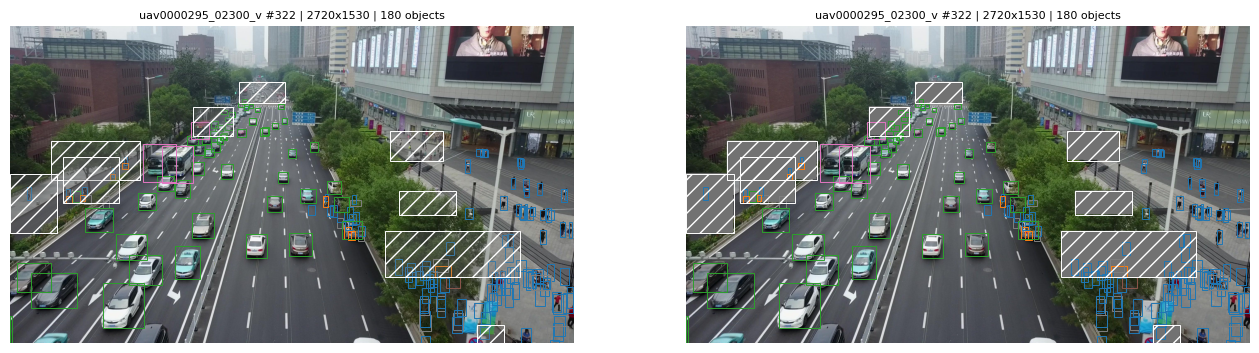

In [20]:
cand = images[(images.ign_frac > 0.03) & (images.ign_frac < 0.4)]
iid = cand.n_obj.idxmax() if len(cand) else images.ign_frac.idxmax()
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
draw_frame(axes[0], iid); draw_frame(axes[1], iid, fill=True)
fig.savefig(IMG_OUT / "ignore_fill.png"); plt.show()

## 5. Folds and shared evaluation
Fixed 3-fold `GroupKFold` by clip over all 63 clips (train + val together), overlap checks, saved to `splits.json`.

In [21]:
splits = common.make_splits(images, n_folds=common.N_FOLDS)
common.save_splits(splits, WORK / "splits.json")
val_sets = [set(f["val_clips"]) for f in splits["folds"]]
assert set().union(*val_sets) == set(images["clip"]) and sum(map(len, val_sets)) == images["clip"].nunique()
assert all(not set(f["train_clips"]) & set(f["val_clips"]) for f in splits["folds"])
assert common.load_splits(WORK / "splits.json") == json.loads(json.dumps(splits))
print({f["fold"]: f"{len(f['train_clips'])} train / {len(f['val_clips'])} val clips" for f in splits["folds"]})

{0: '42 train / 21 val clips', 1: '42 train / 21 val clips', 2: '42 train / 21 val clips'}


**Observations.** Each fold trains on 42 clips and validates on 21; no clip is in both parts.

Fold balance: clips, frames (total, train at stride 20, val at eval stride 10), boxes, density, small-object share, class shares and resolutions of each validation part.

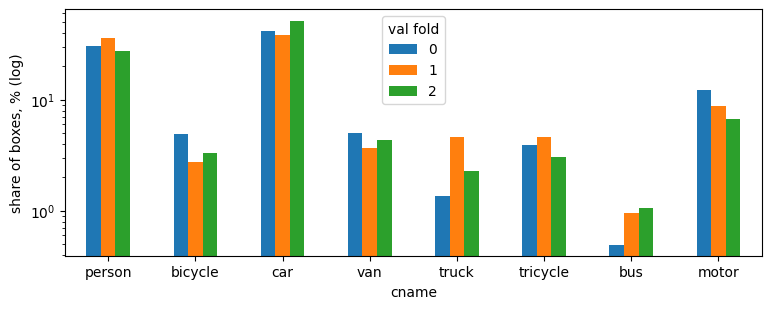

,clips,frames,obj_per_frame,ignore_area_pct,boxes,small_%,train_frames@stride20,val_frames@stride10
fold,,,,,,,,
0,21,9019,51.64,2.34,465732,27.70,922,912
1,21,9029,38.58,2.07,348340,22.77,923,913
2,21,8999,45.07,2.50,405576,21.93,923,909


cname,person,bicycle,car,van,truck,tricycle,bus,motor
fold,,,,,,,,
0,30.52,4.96,41.53,5.01,1.36,3.92,0.50,12.21
1,36.18,2.77,38.29,3.70,4.64,4.66,0.95,8.81
2,27.33,3.33,51.86,4.33,2.31,3.05,1.06,6.73


clips by resolution,1344x756,1360x765,1904x1071,1920x1080,2688x1512,2720x1530,3840x2160
fold,,,,,,,
0,5,0,12,0,3,1,0
1,5,0,10,1,5,0,0
2,3,1,10,0,4,2,1


In [22]:
images["fold"] = images["clip"].map(common.clip_to_fold(splits))
obj["fold"] = obj.img_id.map(images.fold)
clip_stats["fold"] = clip_stats.index.map(common.clip_to_fold(splits))
fold_tab = images.groupby("fold").agg(clips=("clip", "nunique"), frames=("img_id", "size"),
                                      obj_per_frame=("n_obj", "mean"), ignore_area_pct=("ign_frac", "mean"))
fold_tab["ignore_area_pct"] *= 100
fold_tab["boxes"] = obj.groupby("fold").size()
fold_tab["small_%"] = (obj.size_cat == "small").groupby(obj.fold).mean().mul(100)
fold_tab["train_frames@stride20"] = [len(common.fold_images(images, splits, k, "train", common.TRAIN_STRIDE)) for k in fold_tab.index]
fold_tab["val_frames@stride10"] = [len(common.fold_images(images, splits, k, "val", common.EVAL_STRIDE)) for k in fold_tab.index]
fold_cls = pd.crosstab(obj.fold, obj.cname, normalize="index").mul(100).reindex(columns=common.CLASSES, fill_value=0)
fig, ax = plt.subplots(figsize=(9, 3.2))
fold_cls.T.plot.bar(ax=ax, logy=True, rot=0); ax.set_ylabel("share of boxes, % (log)"); ax.legend(title="val fold")
fig.savefig(IMG_OUT / "fold_balance.png"); plt.show()
display(fold_tab.round(2)); display(fold_cls.round(2))
pd.crosstab(clip_stats.fold, clip_stats.width.astype(str) + "x" + clip_stats.height.astype(str), rownames=["fold"], colnames=["clips by resolution"])

**Observations.** GroupKFold balances the number of frames (about 9,000 per fold) but not the content: density 39–52 objects per frame, car share 38–52 %, truck 1.4–4.6 %. Differences between folds are therefore expected, so every result is reported as mean ± std across folds plus pooled OOF.

Sanity check of `common.evaluate` on fold 0: GT as predictions; GT plus higher-scored false positives inside ignored regions; the same false positives on background; jittered GT with random scores.

In [23]:
ids = common.fold_images(images, splits, 0, "val", common.EVAL_STRIDE).img_id.to_numpy()
gt_pred = obj.loc[obj.img_id.isin(ids), ["img_id", "cls", "x", "y", "w", "h"]].assign(score=0.9)
g = ign[ign.img_id.isin(ids)]
fp_ign = pd.DataFrame({"img_id": g.img_id, "cls": rng.integers(0, 8, len(g)), "x": g.x + g.w / 4, "y": g.y + g.h / 4,
                       "w": g.w / 2, "h": g.h / 2, "score": 0.99})
sz = images.loc[np.repeat(ids, 30), ["width", "height"]].to_numpy(float)
fp_bg = pd.DataFrame({"img_id": np.repeat(ids, 30), "cls": rng.integers(0, 8, len(sz)), "x": rng.random(len(sz)) * (sz[:, 0] - 24),
                      "y": rng.random(len(sz)) * (sz[:, 1] - 24), "w": 24.0, "h": 24.0, "score": 0.99})
jit = rng.normal(0, 0.15, (len(gt_pred), 2))
noisy = gt_pred.assign(x=gt_pred.x + jit[:, 0] * gt_pred.w, y=gt_pred.y + jit[:, 1] * gt_pred.h, score=rng.random(len(gt_pred)))
tests = {"GT as predictions": gt_pred, "GT + FP inside ignore": pd.concat([gt_pred, fp_ign]),
         "GT + FP on background": pd.concat([gt_pred, fp_bg]), "jittered GT, random scores": noisy}
t0 = time.time()
coco_gt = common.make_coco_gt(images, anns, ids)
ev = pd.DataFrame({k: common.evaluate(v, images, anns, ids, coco_gt=coco_gt) for k, v in tests.items()}).T
print(f"{len(ids)} frames | {(time.time() - t0) / len(tests):.1f}s per evaluation")
ev[["mAP", "AP50", "AP75", "AP_small", "AR500"]].round(4)

912 frames | 33.0s per evaluation


,mAP,AP50,AP75,AP_small,AR500
GT as predictions,0.9988,1.0000,1.0000,1.0000,1.0000
GT + FP inside ignore,0.9988,1.0000,1.0000,1.0000,1.0000
GT + FP on background,0.4622,0.4638,0.4632,0.2507,1.0000
"jittered GT, random scores",0.2175,0.6914,0.0821,0.2594,0.3628


**Observations.**
- GT as predictions gives AP50 = AP75 = 1 (mAP 0.9988; the small gap appears only at IoU thresholds above 0.75 and is the same for every model).
- False positives inside ignored regions do not change the metric, while the same boxes on background drop mAP to 0.46: ignored regions are handled correctly (each region is expanded to all 8 classes as `iscrowd=1`).
- One evaluation of 912 frames takes about 33 s.

OOF aggregation (per fold, mean ± std, pooled OOF) and logging, tested on synthetic predictions. Written to a separate file so the real experiment log stays clean.

In [24]:
fold_preds = {}
for k in range(common.N_FOLDS):
    ids_k = common.fold_images(images, splits, k, "val", common.EVAL_STRIDE).img_id.to_numpy()
    p = obj.loc[obj.img_id.isin(ids_k), ["img_id", "cls", "x", "y", "w", "h"]]
    fold_preds[k] = p.assign(score=rng.random(len(p)), x=p.x + rng.normal(0, 2, len(p)))
oof = common.evaluate_oof(fold_preds, images, anns, splits)
common.log_results(oof, path=WORK / "results_selftest.csv", owner="A", model="selftest", experiment="eval_selftest",
                   train_stride=common.TRAIN_STRIDE, eval_stride=common.EVAL_STRIDE, imgsz=common.IMGSZ)
display(oof[["mAP", "AP50", "AP_small", "AR500"]].round(4))
pd.read_csv(WORK / "results_selftest.csv").iloc[:, :12]

,mAP,AP50,AP_small,AR500
0,0.8360,0.9927,0.6786,0.8999
1,0.8425,0.9932,0.6692,0.9039
2,0.8443,0.9898,0.6884,0.9058
mean,0.8409,0.9919,0.6787,0.9032
std,0.0036,0.0015,0.0079,0.0025
oof,0.8394,0.9898,0.6872,0.9034


,run_id,timestamp,owner,model,experiment,fold,train_stride,eval_stride,imgsz,epochs,mAP,AP50
0,eval_selftest_20261105180449,2026-11-05 18:04:49,A,selftest,eval_selftest,0,20,10,640,NaN,0.8360,0.9927
1,eval_selftest_20261105180449,2026-11-05 18:04:49,A,selftest,eval_selftest,1,20,10,640,NaN,0.8425,0.9932
2,eval_selftest_20261105180449,2026-11-05 18:04:49,A,selftest,eval_selftest,2,20,10,640,NaN,0.8443,0.9898
3,eval_selftest_20261105180449,2026-11-05 18:04:49,A,selftest,eval_selftest,mean,20,10,640,NaN,0.8409,0.9919
4,eval_selftest_20261105180449,2026-11-05 18:04:49,A,selftest,eval_selftest,std,20,10,640,NaN,0.0036,0.0015
5,eval_selftest_20261105180449,2026-11-05 18:04:49,A,selftest,eval_selftest,oof,20,10,640,NaN,0.8394,0.9898


**Observations.** Per-fold, mean ± std and pooled OOF rows are computed and saved in the `results.csv` format.

Submission writing: synthetic boxes (including ones outside the frame) are clipped and checked against the expected ids and format.

In [25]:
dummy = test_index.head(5)[["image_id"]].merge(
    pd.DataFrame({"cls": [2, 0], "score": [0.9, 0.5], "x": [10.0, -5.0], "y": [20.0, 30.0], "w": [30.0, 40.0], "h": [40.0, 4000.0]}), how="cross")
path = common.write_submission(dummy, test_index, WORK / "submission_selftest.csv")
sample_path = SAMPLE_SUB or WORK / "sample_submission_from_test_index.csv"
if not SAMPLE_SUB:
    sample_sub.to_csv(sample_path, index=False)
print(common.check_submission(path, sample_path))
pd.read_csv(path, keep_default_na=False).head(3)

{'rows': 3811, 'same_ids_and_order': True, 'groups_of_6': True, 'max_dets': 2, 'classes_ok': True, 'empty_rows': 3806}


,image_id,PredictionString
0,clip_001_0000001,2 0.9000 10.0 20.0 30.0 40.0 0 0.5000 0.0 30.0...
1,clip_001_0000002,2 0.9000 10.0 20.0 30.0 40.0 0 0.5000 0.0 30.0...
2,clip_001_0000003,2 0.9000 10.0 20.0 30.0 40.0 0 0.5000 0.0 30.0...


**Observations.** Ids and order match, each prediction has 6 values, and out-of-frame boxes are clipped.

## 6. Torchvision dataset (Person A)
Fold 0 datasets from `tv_dataset.py`: train clips at stride 20 with horizontal flip, val clips at stride 10. Ignored regions are filled with gray (114); frames are resized so that the longest side is 640 px.

In [26]:
from tv_dataset import VisDroneDet, make_loader, to_device, preds_to_df
f0 = splits["folds"][0]
ds_tr = VisDroneDet(images, anns, clips=f0["train_clips"], stride=common.TRAIN_STRIDE, max_side=common.IMGSZ, train=True)
ds_va = VisDroneDet(images, anns, clips=f0["val_clips"], stride=common.EVAL_STRIDE, max_side=common.IMGSZ, train=False)
print("train frames:", len(ds_tr), "| val frames:", len(ds_va))

train frames: 922 | val frames: 912


One batch: tensor shape and type, number of boxes, labels (1–8; 0 is background in torchvision) and box validity.

In [27]:
dl = make_loader(ds_tr, batch_size=4, num_workers=2)
t0 = time.time()
imgs, tgts = next(iter(dl))
print(f"first batch: {time.time() - t0:.1f}s")
for im, t in zip(imgs, tgts):
    b = t["boxes"]
    ok = bool(((b[:, 2] > b[:, 0]) & (b[:, 3] > b[:, 1])).all() and (b >= 0).all()
              and (b[:, 2] <= im.shape[2]).all() and (b[:, 3] <= im.shape[1]).all())
    print(tuple(im.shape), im.dtype, "| boxes", tuple(b.shape), "| labels", sorted(t["labels"].unique().tolist()),
          "| scale", round(t["scale"], 3), "| orig", t["orig_size"], "| valid:", ok)
x, y = to_device(imgs, tgts, "cpu")
print("after to_device:", x[0].dtype, round(float(x[0].min()), 3), round(float(x[0].max()), 3))

first batch: 0.4s
(3, 360, 640) torch.uint8 | boxes (48, 4) | labels [1, 2, 3, 7, 8] | scale 0.336 | orig (1071, 1904) | valid: True
(3, 360, 640) torch.uint8 | boxes (80, 4) | labels [1, 3, 4, 5, 6, 8] | scale 0.336 | orig (1071, 1904) | valid: True
(3, 360, 640) torch.uint8 | boxes (49, 4) | labels [1, 2, 3, 5, 6, 8] | scale 0.336 | orig (1071, 1904) | valid: True
(3, 360, 640) torch.uint8 | boxes (22, 4) | labels [1, 3, 5, 7] | scale 0.336 | orig (1071, 1904) | valid: True
after to_device: torch.float32 0.0 1.0


**Observations.** Frames are 640×360 uint8 with valid boxes inside the image. Conversion to float [0, 1] happens on the device, so host → GPU copies are 4× smaller.

Loading speed from disk (every frame is decoded and resized each time).

In [28]:
def loader_speed(dl, n_batches=20):
    t0, n = time.time(), 0
    for i, (imgs, tgts) in enumerate(dl):
        n += len(imgs)
        if i == n_batches - 1:
            break
    return n / (time.time() - t0), imgs, tgts

speed, imgs, tgts = loader_speed(dl)
print(f"from disk: {speed:.1f} images/s with {dl.num_workers} workers")

from disk: 31.1 images/s with 2 workers


Cache all fold-0 train frames in RAM (already filled and resized) and measure the loading speed again.

In [29]:
t0 = time.time()
gb = ds_tr.precache()
print(f"precache: {time.time() - t0:.0f}s for {len(ds_tr)} frames, {gb:.2f} GB in RAM")
dl_cached = make_loader(ds_tr, batch_size=4)
speed, imgs, tgts = loader_speed(dl_cached)
print(f"from RAM: {speed:.1f} images/s with {dl_cached.num_workers} workers")

precache: 18s for 922 frames, 0.64 GB in RAM
from RAM: 239.6 images/s with 4 workers


**Observations.** Caching takes 18 s and 0.64 GB for 922 frames and raises the loading speed from 31 to 240 images/s, so the GPU will not wait for data. The disk run used 2 workers and the cached run 4; even per worker, the cache is about 4× faster.

The last batch as the model sees it: resized frames, gray ignored regions, boxes after flipping.

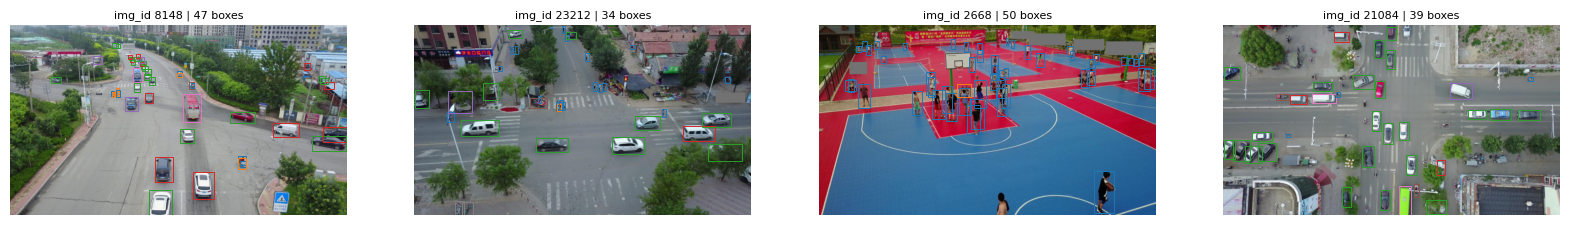

In [30]:
fig, axes = plt.subplots(1, 4, figsize=(20, 3.6))
for ax, im, t in zip(axes, imgs, tgts):
    ax.imshow(im.permute(1, 2, 0).numpy())
    for (x1, y1, x2, y2), l in zip(t["boxes"].tolist(), t["labels"].tolist()):
        ax.add_patch(mpatches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, ec=COLORS[l - 1], lw=0.7))
    ax.set_title(f"img_id {t['image_id']} | {len(t['boxes'])} boxes", fontsize=8); ax.axis("off")
fig.savefig(IMG_OUT / "batch_sanity.png"); plt.show()

Round-trip check for future predictions: val targets are passed as "predictions", converted back to original pixels with `preds_to_df` and evaluated.

In [31]:
outs, tg = [], []
for i in np.linspace(0, len(ds_va) - 1, min(60, len(ds_va))).astype(int):
    _, t = ds_va[i]
    outs.append({"boxes": t["boxes"], "labels": t["labels"], "scores": torch.ones(len(t["labels"]))})
    tg.append(t)
rt = preds_to_df(outs, tg)
r = common.evaluate(rt, images, anns, [t["image_id"] for t in tg])
print({k: round(r[k], 4) for k in ["mAP", "AP50", "AP_small"]})

{'mAP': 0.9864, 'AP50': 0.9864, 'AP_small': 0.9986}


**Observations.** mAP 0.986 ≈ 1. The gap comes from boxes dropped under ignored regions, which still count as GT. The coordinate conversion is correct.

## 7. Box statistics and anchors (Person A)
Per fold, training boxes only (not covered by ignore): size and aspect ratio (h/w) at the 640 px input scale.

In [32]:
sc = common.IMGSZ / np.maximum(obj.width, obj.height)
obj["w640"], obj["h640"] = obj.w * sc, obj.h * sc
obj["ar"] = obj.h / np.maximum(obj.w, 1e-3)
q = [0.05, 0.25, 0.5, 0.75, 0.95]
stats = {}
for f in splits["folds"]:
    o = obj[obj["clip"].isin(f["train_clips"]) & (obj.ign_cover < 0.5)]
    stats[(f["fold"], "sqrt_area@640")] = np.sqrt(o.w640 * o.h640).quantile(q).values
    stats[(f["fold"], "h/w")] = o.ar.quantile(q).values
display(pd.DataFrame(stats, index=[f"q{int(v * 100)}" for v in q]).T.round(2))
obj.groupby("cname").ar.median().reindex(common.CLASSES).round(2).rename("median h/w").to_frame().T

q5    q25    q50    q75    q95
0 sqrt_area@640  6.59  10.94  15.95  22.85  41.65
  h/w            0.40   0.70   1.07   1.76   2.58
1 sqrt_area@640  6.87  10.78  15.21  21.87  42.14
  h/w            0.41   0.67   1.04   1.67   2.50
2 sqrt_area@640  6.89  11.05  15.06  21.43  40.49
  h/w            0.42   0.72   1.12   1.77   2.60

cname,person,bicycle,car,van,truck,tricycle,bus,motor
median h/w,2.0,1.08,0.79,0.88,0.93,0.95,0.96,1.24


**Observations.** Statistics are stable across folds: median size 15–16 px at 640, 90 % of boxes between 7 and 42 px. Aspect ratios range from 0.4 to 2.6; persons are tall (h/w ≈ 2), cars are wide (≈ 0.8).

Helpers: k-means with 1 − IoU distance (as in YOLOv2), 1D k-means in log space, and an anchor grid that reproduces torchvision's `AnchorGenerator` for P3–P7 (strides 8–128).

In [33]:
def wh_iou(wh, c):
    inter = np.minimum(wh[:, None, 0], c[None, :, 0]) * np.minimum(wh[:, None, 1], c[None, :, 1])
    return inter / (wh.prod(1)[:, None] + c.prod(1)[None] - inter)

def kmeans_iou(wh, k, iters=300, seed=common.SEED):
    c = wh[np.random.default_rng(seed).choice(len(wh), k, replace=False)]
    for _ in range(iters):
        a = wh_iou(wh, c).argmax(1)
        new = np.array([np.median(wh[a == j], 0) if (a == j).any() else c[j] for j in range(k)])
        if np.allclose(new, c):
            break
        c = new
    c = c[np.argsort(c.prod(1))]
    return c, float(wh_iou(wh, c).max(1).mean())

def kmeans_1d(v, k, iters=100):
    c = np.quantile(v, (np.arange(k) + 0.5) / k)
    for _ in range(iters):
        a = np.abs(v[:, None] - c[None]).argmin(1)
        new = np.array([v[a == j].mean() if (a == j).any() else c[j] for j in range(k)])
        if np.allclose(new, c):
            break
        c = new
    return np.sort(c)

def tv_sizes(bases):
    return tuple(tuple(max(1, int(b * 2 ** (i / 3))) for i in range(3)) for b in bases)

def grid_anchors(h, w, sizes, ratios, strides=(8, 16, 32, 64, 128)):
    out = []
    for s, sz, rt in zip(strides, sizes, ratios):
        hr = np.sqrt(np.asarray(rt, float)); wr = 1 / hr
        ws = (wr[:, None] * np.asarray(sz, float)[None]).ravel(); hs = (hr[:, None] * np.asarray(sz, float)[None]).ravel()
        base = np.round(np.stack([-ws, -hs, ws, hs], 1) / 2)
        sx, sy = np.meshgrid(np.arange(math.ceil(w / s)) * s, np.arange(math.ceil(h / s)) * s)
        shifts = np.stack([sx.ravel(), sy.ravel(), sx.ravel(), sy.ravel()], 1)
        out.append((shifts[:, None] + base[None]).reshape(-1, 4))
    return torch.as_tensor(np.concatenate(out), dtype=torch.float32)

def best_anchor_iou(boxes, shapes, sizes, ratios):
    from torchvision.ops import box_iou
    cache, best = {}, []
    for b, (h, w) in zip(boxes, shapes):
        if len(b) == 0:
            continue
        key = (math.ceil(h / 32) * 32, math.ceil(w / 32) * 32)
        if key not in cache:
            cache[key] = grid_anchors(*key, sizes, ratios)
        best.append(box_iou(torch.as_tensor(b, dtype=torch.float32), cache[key]).max(1).values.numpy())
    return np.concatenate(best) if best else np.zeros(0)

Per fold: k-means (k = 9) on training (w, h) and a k-means-based RetinaNet config (5 levels × 3 sizes × 3 ratios). On validation frames we measure the share of GT boxes that have an anchor with IoU ≥ 0.5 / 0.4, for default anchors, anchors scaled ×0.5 and ×0.25, and k-means anchors — at 640 px (all folds) and 1280 px (fold 0).

In [34]:
mk = lambda bases, ratios=(0.5, 1.0, 2.0): dict(sizes=tv_sizes(bases), ratios=(tuple(ratios),) * 5)
CONFIGS = {"default": mk([32, 64, 128, 256, 512]), "x0.5": mk([16, 32, 64, 128, 256]), "x0.25": mk([8, 16, 32, 64, 128])}
ocover, osize = obj.ign_cover.to_numpy(), obj.size_cat.to_numpy()
anchor_cfg, cov_rows = {}, []
t0 = time.time()
for imgsz, folds, n_frames in [(640, [0, 1, 2], 300), (1280, [0], 150)]:
    for k in folds:
        f = splits["folds"][k]
        o = obj[obj["clip"].isin(f["train_clips"]) & (obj.ign_cover < 0.5)]
        o = o.sample(min(len(o), 200_000), random_state=common.SEED)
        sc = imgsz / np.maximum(o.width, o.height)
        wh = np.column_stack([o.w * sc, o.h * sc]).astype(np.float64)
        wh = wh[(wh > 0).all(1)]
        c9, miou = kmeans_iou(wh, 9)
        bases = np.exp(kmeans_1d(np.log(np.sqrt(wh.prod(1))), 5)) / 2 ** (1 / 3)
        ratios = np.round(np.exp(kmeans_1d(np.log(wh[:, 1] / wh[:, 0]), 3)), 2)
        cfgs = {**CONFIGS, "kmeans": mk(bases, ratios.tolist())}
        va = common.fold_images(images, splits, k, "val", common.TRAIN_STRIDE)
        va = va.sample(min(len(va), n_frames), random_state=common.SEED)
        boxes, shapes, cats = [], [], []
        for iid, r in va.iterrows():
            s = imgsz / max(r.width, r.height)
            a, b = np.searchsorted(oid, [iid, iid + 1])
            sel = ocover[a:b] < 0.5
            bb = oxywh[a:b][sel] * s
            boxes.append(np.column_stack([bb[:, 0], bb[:, 1], bb[:, 0] + bb[:, 2], bb[:, 1] + bb[:, 3]]))
            shapes.append((round(r.height * s), round(r.width * s)))
            cats.append(osize[a:b][sel])
        cats = np.concatenate(cats)
        for name, cfg in cfgs.items():
            best = best_anchor_iou(boxes, shapes, **cfg)
            row = {"imgsz": imgsz, "fold": k, "anchors": name, "IoU>=0.5 %": 100 * (best >= 0.5).mean(),
                   "IoU>=0.4 %": 100 * (best >= 0.4).mean(), "mean best IoU": best.mean()}
            row.update({f"{c} IoU>=0.5 %": 100 * (best[cats == c] >= 0.5).mean() if (cats == c).any() else np.nan
                        for c in ["small", "medium", "large"]})
            cov_rows.append(row)
        anchor_cfg[f"fold{k}@{imgsz}"] = {
            "kmeans_wh_k9": np.round(c9, 2).tolist(), "kmeans_k9_mean_iou": round(miou, 4),
            "retinanet": {n: {"sizes": c["sizes"], "aspect_ratios": c["ratios"]} for n, c in cfgs.items()}}
cov = pd.DataFrame(cov_rows)
print(f"{time.time() - t0:.0f}s")
display(pd.DataFrame({k: {"k9 mean IoU": v["kmeans_k9_mean_iou"], "kmeans sizes": v["retinanet"]["kmeans"]["sizes"],
                          "kmeans ratios": v["retinanet"]["kmeans"]["aspect_ratios"][0]} for k, v in anchor_cfg.items()}).T)
cov.drop(columns="fold").groupby(["imgsz", "anchors"], sort=False).agg(["mean", "std"]).round(1)

257s


,k9 mean IoU,kmeans sizes,kmeans ratios
fold0@640,0.7166,"((4, 6, 7), (8, 10, 13), (12, 15, 20), (19, 24...","(0.5, 1.02, 2.07)"
fold1@640,0.7318,"((5, 6, 8), (8, 10, 13), (12, 15, 20), (19, 24...","(0.51, 1.01, 1.97)"
fold2@640,0.7306,"((5, 6, 8), (8, 10, 13), (12, 15, 19), (19, 23...","(0.52, 1.03, 2.04)"
fold0@1280,0.7166,"((9, 12, 15), (16, 20, 26), (25, 31, 40), (38,...","(0.5, 1.02, 2.07)"


IoU>=0.5 %      IoU>=0.4 %      mean best IoU      small IoU>=0.5 %      medium IoU>=0.5 %      large IoU>=0.5 %     
                    mean  std       mean  std          mean  std             mean  std              mean  std             mean  std
imgsz anchors                                                                                                                      
640   default       23.9  3.4       31.5  5.1           0.3  0.0              0.0  0.0              19.5  3.6             99.4  0.7
      x0.5          64.5  2.4       76.9  2.6           0.5  0.0             15.1  2.6              77.3  3.6             99.4  0.3
      x0.25         49.7  0.5       81.4  0.9           0.5  0.0             36.7  2.3              53.3  0.7             56.8  0.6
      kmeans        17.4  1.3       37.1  3.0           0.4  0.0             21.9  3.7              17.9  1.0              5.9  0.5
1280  default       70.6  NaN       78.1  NaN           0.6  NaN             16.6  NaN              89.5  NaN             99.8  NaN
      x0.5          95.5  NaN       99.0  NaN           0.7  NaN             85.4  NaN              99.4  NaN             98.9  NaN
      x0.25         57.0  NaN       90.4  NaN           0.5  NaN             52.1  NaN              59.1  NaN             57.4  NaN
      kmeans        58.5  NaN       88.8  NaN           0.5  NaN             73.1  NaN              57.9  NaN             24.9  NaN

**Observations.**
- Default RetinaNet anchors (32–512 px) cover **0 %** of small objects at 640 px.
- k-means aspect ratios are (0.5, 1.0, 2.0), the same as the defaults: the problem is anchor **size**, not shape.
- Placing k-means sizes on all levels is worse (17 %): tiny anchors land on coarse levels (stride 64–128), where they cannot line up with objects. Anchor sizes must follow the level stride.
- At 640 px: ×0.5 covers 65 % of all boxes but only 15 % of small ones; ×0.25 covers 50 % and 37 %. At 1280 px, ×0.5 covers 95.5 % of all and 85 % of small boxes.
- These numbers are an upper bound of anchor–GT matching, not detection accuracy (torchvision's matcher also gives every GT its best anchor, even below IoU 0.4).
- Plan for RetinaNet: default anchors as the baseline, ×0.5 and ×0.25 as tuned versions at 640; ×0.5 at 1280 is a candidate for the final pipeline.

k-means centroids (fold 0) over training box sizes; all anchor configs are saved to `anchors.json` for the RetinaNet notebook.

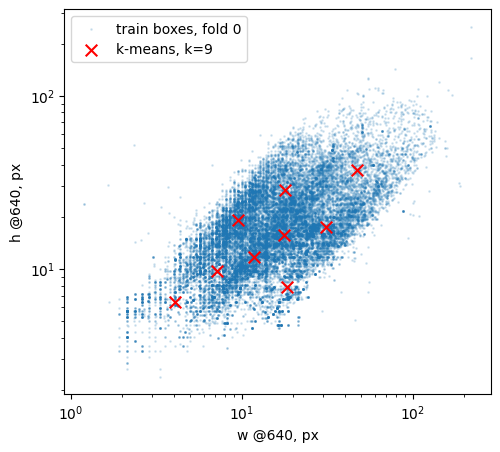

In [35]:
o = obj[obj["clip"].isin(splits["folds"][0]["train_clips"]) & (obj.ign_cover < 0.5)]
o = o.sample(min(len(o), 30_000), random_state=common.SEED)
c = np.array(anchor_cfg["fold0@640"]["kmeans_wh_k9"])
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.scatter(o.w640, o.h640, s=1, alpha=0.15, label="train boxes, fold 0")
ax.scatter(c[:, 0], c[:, 1], c="red", marker="x", s=70, label="k-means, k=9")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("w @640, px"); ax.set_ylabel("h @640, px"); ax.legend()
fig.savefig(IMG_OUT / "anchors_kmeans.png"); plt.show()
with open(WORK / "anchors.json", "w") as fh:
    json.dump(anchor_cfg, fh, indent=1)

## 8. Saved artifacts
Per-clip statistics and the list of files to copy to the repository: `splits.json`, `anchors.json`, `clip_stats.csv` and plots in `images/`. Files with `selftest` in the name are not committed.

In [36]:
clip_stats.round(3).to_csv(WORK / "clip_stats.csv")
for p in sorted([*WORK.glob("*.json"), *WORK.glob("*.csv"), *IMG_OUT.glob("*.png")]):
    print(f"{str(p):<60} {p.stat().st_size / 1e3:8.0f} KB")

/kaggle/working/anchors.json                                       10 KB
/kaggle/working/clip_stats.csv                                      5 KB
/kaggle/working/images/anchors_kmeans.png                         159 KB
/kaggle/working/images/batch_sanity.png                           786 KB
/kaggle/working/images/class_distribution.png                      18 KB
/kaggle/working/images/class_share_per_clip.png                    29 KB
/kaggle/working/images/fold_balance.png                            21 KB
/kaggle/working/images/gt_samples.png                            1877 KB
/kaggle/working/images/ignore_fill.png                            633 KB
/kaggle/working/images/ignore_regions.png                          32 KB
/kaggle/working/images/object_sizes.png                            53 KB
/kaggle/working/images/objects_per_frame.png                       50 KB
/kaggle/working/images/sizes_per_clip.png                          49 KB
/kaggle/working/images/stride_analysis.png         

## Summary: decisions for the next notebooks
- **Validation:** fixed 3-fold `GroupKFold` by clip (`splits.json`); metrics reported as mean ± std across folds and pooled OOF.
- **Protocol:** train frames at stride 20, validation frames at stride 10, longest side 640 px, seed 42.
- **Ignored regions:** one copy per region; gray fill (114) in training, `iscrowd=1` for all classes in evaluation; boxes ≥ 50 % covered are dropped.
- **Detections per image:** 300 (max 180 objects per frame).
- **Anchors:** tune the size (×0.5, ×0.25), keep ratios (0.5, 1, 2).
- **Final pipeline candidates:** higher resolution (1280) or SAHI for small objects; multi-scale augmentation for unseen test resolutions; per-class AP to track rare classes (bus, truck).
- **Speed:** cache training frames in RAM (`precache`).